<a href="https://colab.research.google.com/github/vazquezsanchezdiegoamaury258/Diplomado/blob/main/DistribucionesContinuasParteI_DiegoAmaury.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variables aleatorias (absolutamente) continuas

**Definición.** Una variable aleatoria absolutamente continua es aquella para la cual existe una función $f_X$ no negativa, llamada función de densidad, tal que:
$$
F_X(x) = \mathbb{P}(X\leq x) = \int_{-\infty}^{x} f_X(y) dy, \quad x\in \mathbb{R}
$$

**Lema.** Sea $F_X$ una función de distribución. Supongamos que $F_X$ es derivable y que su derivada es continua en $(a, b)$, donde:
$ a = \inf \{ x \in \mathbb{R} \mid F_X(x) > 0 \}, \quad b = \sup \{ x \in \mathbb{R} \mid F_X(x) < 1 \}$
entonces, la función de densidad se puede obtener como:
$$ f_X(x) =
\begin{cases}
F'_X(x), & \text{si } x \in (a, b), \\
0, & \text{e.o.c.}
\end{cases}$$

Es decir,
$$ \frac{dF_X(x)}{dx} = f_X(x)$$


In [ ]:
import numpy as np # Importamos Numpy
import numpy.random as npr # para generar numeros aleatorios

import scipy.stats as sps # Importamos el modulo SciPy
from scipy.stats import randint # para trabajar una uniforme discreta en un rango de enteros

import matplotlib.pyplot as plt #Visualizar datos

import random # para generar numeros aleatorios

## Variable aleatoria uniforme (rectangular) sobre el intervalo $(a,b)$.

Una variable aleatoria $X$ se dice que tiene distribución uniforme continua  en el intervalo $(a,b)$ con $a,b\in\mathbb{R}$, si su función de densidad esta dada por:
$$f_{X}(x)=\begin{cases}
	\frac{1}{b-a} &\quad \text{si } a< x < b\\
	\qquad 0 &\quad \text{en otro caso}  
\end{cases}$$

**Notación.** $X\sim \text{Unif}(a,b)$ $\text{Unif}[a,b]$

**Obs:**
* La distribución uniforme continua en $(a,b)$ es simétrica.
* A los intervalos de la misma longitud contenidos en $(a,b)$ se les asigna la misma probabilidad. Esto se representa gráficamente con la probabilidad de que $X$ se encuentre en el intervalo $(s,t)$:


La función de distribución de $X\sim Unif((a,b))$ esta dada por:
$$F_{X}(x)=\begin{cases}
	 0 &\quad \text{si } x\le a \\
	\frac{x-a}{b-a} &\quad \text{si } a<x<b\\
	 1 &\quad \text{si } x\ge b  
\end{cases}$$

La esperanza de una variable aleatoria uniforme es la siguiente,
$$\begin{align*}
\mathbb{E}[X] &= \int_{a}^{b}xf_{X}(x)dx = \int_{a}^{b}x\frac{1}{b-a}dx = \frac{1}{b-a}\int_{a}^{b}xdx  = \frac{1}{b-a}\left[\frac{x^{2}}{2}\right]_{a}^{b} \\ &= \frac{1}{b-a}\left[\frac{b^{2}}{2}-\frac{a^{2}}{2}\right] =  \frac{b^{2}-a^{2}}{2(b-a)} = \frac{(b-a)(b+a)}{2(b-a)} = \frac{a+b}{2}.
\end{align*}$$

Para calcular la varianza, primero vamos a calcular el segundo momento
$$\begin{align*}
\mathbb{E}[X^{2}] &= \int_{a}^{b}x^{2}f_{X}(x)dx = \int_{a}^{b}x^{2}\frac{1}{b-a}dx = \frac{1}{b-a}\int_{a}^{b}x^{2}dx \\ &= \frac{1}{b-a}\left[\frac{x^{3}}{3}\right]_{a}^{b} = \frac{1}{b-a}\left[\frac{b^{3}}{3}-\frac{a^{3}}{3}\right] =  \frac{b^{3}-a^{3}}{3(b-a)}.
\end{align*}$$

Por lo que se tiene lo siguiente

$$Var(X) = \mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} =\frac{b^{3}-a^{3}}{3(b-a)}-\left(\frac{a+b}{2}\right)^{2} = \frac{(b-a)^{2}}{12}.$$

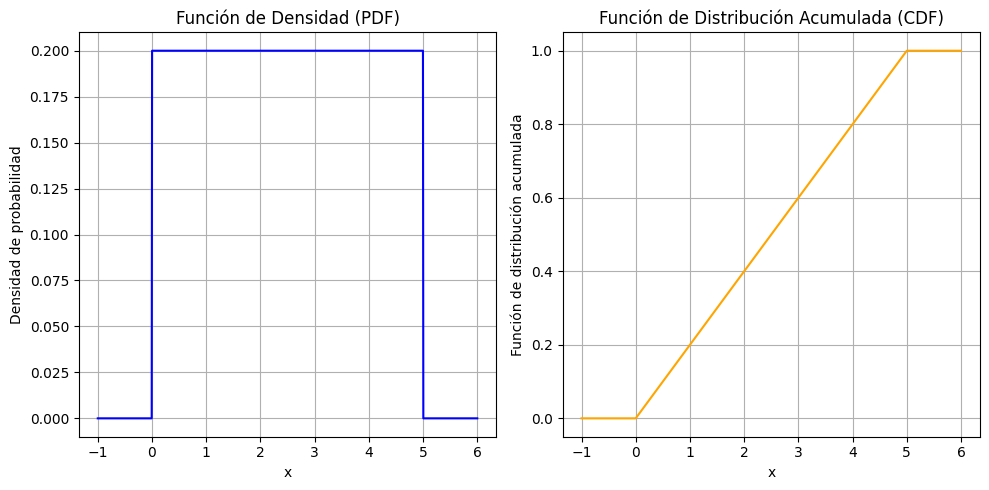

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import uniform# Parámetros de la distribución uniforme
a = 0  # límite inferior
b = 5  # límite superior

#Vamos a crear el objeto de la dist unif usando scipy
unif_dist = uniform(loc=a, scale=b-a)

# Generar valores de x
x = np.linspace(-1, 6, 1000)

# Calcular la función densidad
pdf_values = unif_dist.pdf(x)

# Calcular la función de distribución
cdf_values = unif_dist.cdf(x)

# Graficar la PDF
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(x, pdf_values, label='PDF', color='blue') # para cada gráfica
plt.xlabel('x')
plt.ylabel('Densidad de probabilidad')
plt.title('Función de Densidad (PDF)')
plt.grid(True)

# Graficar la CDF
plt.subplot(1, 2, 2)
plt.plot(x, cdf_values, label='CDF', color='orange')
plt.xlabel('x')
plt.ylabel('Función de distribución acumulada')
plt.title('Función de Distribución Acumulada (CDF)')
plt.grid(True)

plt.tight_layout()
plt.show()

**Ejemplo.** 	Sea $X\sim Unif((-3,2))$. Vamos a calcular: $P(X\ge 0)$ y
$P(-5 \le X \le 1/2)$.

**Solución.** La función de densidad de esta variable aleatoria esta dada por:
$$f_{X}(x)=\begin{cases}
	\quad \frac{1}{5} &\quad \text{si } -3\le x \le 2\\
	\quad 0 &\quad \text{e.o.c}  
\end{cases}$$
Entonces,

$$\begin{align}
\mathbb{P}(X\ge 0) &= \int_{0}^{2}\frac{1}{5}dx=\frac{1}{5}x\Big|_{0}^{2}=\frac{2}{5} \\
\mathbb{P}(-5 \le X \le 1/2) &= \int_{-5}^{-3}f_{X}(x)dx+\int_{-3}^{1/2}\frac{1}{5}dx=\frac{1}{5}x\Big|_{-3}^{1/2}=\frac{1}{5}\left(\frac{1}{2}+3\right)=\frac{7}{10}
\end{align}$$

Utilizando la $F_X$,
$$F_X(x):=\mathbb{P}(X\le x)$$
se tiene:

- $\mathbb{P}(X\ge 0)=1-F_X(0)$
- $\mathbb{P}(-5\le X \le 1/2) = F_{X}(1/2)-F_{X}(-5)$

In [6]:
a = -3
b = 2
unif_dist = uniform(loc=a, scale=b-a)

#calc probabilidad de que x sea mayor a 0
p_0 = 1-unif_dist.cdf(0)
p_intervalo = unif_dist.cdf(1/2)-unif_dist.cdf(-5)


print(f"P(X>=0) = {p_0}")
print(f"P(-5<=X<=1/2) = {p_intervalo}")

P(X>=0) = 0.4
P(-5<=X<=1/2) = 0.7


$\color{red}{\text{Ejercicio 1.}}$ **(Python)** Un alumno se dirige a la biblioteca para solicitar el préstamo de un libro y decide que no puede esperar más de $10$ minutos en ser atendido. Supongamos que el bibliotecario tarda por lo menos $0.5$ minutos en atender a una persona, entonces es razonable proponer una distribución uniforme en el intervalo $[0.5,10]$ para modelar el comportamiento de la variable $X$ que es el tiempo en ser atendido (en  minutos).

- Da la función de densidad y gráfica.
- ¿Cuál es la probabilidad de que el tiempo en ser atendido sea mayor a $5$ minutos pero menor a $8$ minutos?
- ¿Cuál es la esperanza y varianza?
- Calcula la función de distribución y gráficala, y con ella calcula: $\mathbb{P}(2.51\le X \le 7.99)$.

Veamos el comportamiento de la función conforme se cambia la media.

## Variable aleatoria exponencial con parámetro $\lambda > 0$

La distribución exponencial es una de las distribuciones continuas más utilizadas. A menudo se utiliza para modelar el tiempo transcurrido entre eventos.  
Algunos ejemplos en los que podría utilizarse la distribución exponencial son:

- El tiempo transcurrido en un *call center* hasta recibir la primera llamada del día.
- El tiempo entre terremotos de una determinada magnitud.
- Supongamos una máquina que produce hilo de alambre: la cantidad de metros de alambre hasta encontrar una falla se podría modelar como una exponencial.

Se dice que la variable aleatoria $X$ tiene **distribución exponencial** de parámetro $\lambda > 0$, si su función de densidad está dada por:

$$f_{X}(x)=\begin{cases}
\lambda e^{-\lambda x} & x>0\\
0 & \text{en otro caso}
\end{cases}$$

La esperanza y la varianza son:

$$\mathbb{E}[X]= \frac{1}{\lambda}, \qquad \mathrm{Var}(X)=\frac{1}{\lambda^2}$$

**Notación:** $X \sim \mathrm{Exp}(\lambda)$.

**Propiedad de pérdida de memoria:**

$$\mathbb{P}(X>t+s \mid X>t)=\mathbb{P}(X>s)=e^{-\lambda s}.$$

### Parametrización alternativa (en términos de la media $\lambda$)

La esperanza y la varianza de una distribución exponencial escrita en la forma:

$$f_{X}(x)=\begin{cases}
\frac{1}{\lambda} e^{-\frac{x}{\lambda}} & x>0\\
0 & \text{en otro caso}
\end{cases}$$

son:

$$\mathbb{E}[X]= \int_{0}^{\infty} x f_{X}(x)\,dx = \int_{0}^{\infty} x \frac{1}{\lambda} e^{-\frac{x}{\lambda}}\,dx = \lambda$$

y

\begin{align*}
\mathrm{Var}(X) &= \mathbb{E}[X^2] - (\mathbb{E}[X])^2 \\
&= \int_{0}^{\infty} x^2 f_{X}(x)\,dx - \lambda^2 \\
&= \int_{0}^{\infty} x^2 \frac{1}{\lambda} e^{-\frac{x}{\lambda}}\,dx - \lambda^2 = \lambda^2.
\end{align*}

---

### Ejemplo

Consideremos la variable aleatoria $X$ como el tiempo (en minutos) entre la llegada de dos personas a la fila de una sucursal bancaria. Adicionalmente, el banco ha determinado que solo el $10\%$ de las veces el tiempo que transcurre entre la llegada de una persona y otra es mayor a dos minutos. Esto permite calcular el valor de $\lambda$ bajo la parametrización $f_X(x) = \lambda e^{-\lambda x}$ ($x > 0$), ya que:

$$\mathbb{P}(X > 2) = 0.1$$

entonces:

$$1 - \mathbb{P}(X \le 2) = 1 - F_X(2) = 0.1$$

Notemos que si $X \sim \mathrm{Exp}(\lambda)$ con tasa $\lambda$, entonces $F_X(x) = 1 - e^{-\lambda x}$ para $x > 0$. Por lo tanto, $F_X(2) = 1 - e^{-2\lambda} = 0.9$, es decir, $e^{-2\lambda} = 0.1$. De aquí:

$$-2\lambda = \ln(0.1) \implies \lambda = -\frac{\ln(0.1)}{2} \approx 1.1513$$

Por lo tanto, $X \sim \mathrm{Exp}(1.1513)$.

Ahora queremos calcular la probabilidad de que entre la llegada de una persona y otra transcurra más de un minuto, lo cual puede calcularse de dos formas:

\begin{align*}
\mathbb{P}(X > 1) &= \int_{1}^{\infty} f_{X}(x)\,dx = \int_{1}^{\infty} 1.1513\, e^{-1.1513x}\,dx = e^{-1.1513} \approx 0.3162
\end{align*}

\begin{align*}
\mathbb{P}(X > 1) &= 1 - \mathbb{P}(X \le 1) = 1 - \left[1 - e^{-1.1513}\right] = e^{-1.1513} \approx 0.3162
\end{align*}